# 3.3 Two-way slab: corner panel P1

Panel P1 of the typical floor: 5 m × 6 m, continuous on two adjacent edges. This is the panel with the largest moments.

**Workflow**

| Step | Check | Reference |
|:--|:--|:--|
| 1 | One-way or two-way: ly/lx > 2 → one-way | EC2 5.3.1(5) |
| 2 | Thickness, cover, effective depth, fire | EC2 4.4.1, EN 1992-1-2 |
| 3 | Actions and ULS combination | EN 1990, EN 1991-1-1 |
| 4 | Moments and shears | EC2 5; coefficients |
| 5 | Bending steel, minimum and maximum | EC2 6.1, 9.2.1.1, 9.3.1.1 |
| 6 | Shear without links | EC2 6.2.2 |
| 7 | Deflection | EC2 7.4.2 |
| 8 | Cracking, spacing, secondary steel, curtailment | EC2 7.3.3, 9.3.1 |

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

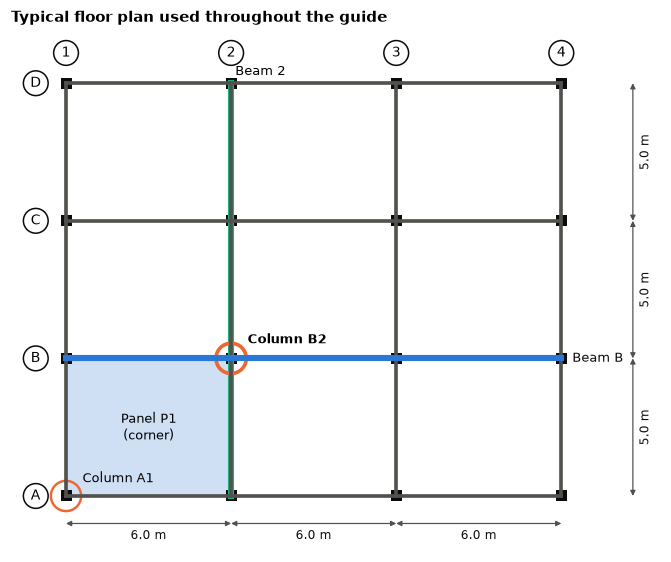

In [2]:
P.sketch_plan()

## Method

EC2 gives no coefficients for two-way slabs. The moments come from BS 8110-1 Table 3.14: panels held down at the corners, with torsion steel. The load n is the EN 1990 value, not the BS 8110 one.

$$m_{sx} = \beta_{sx}\,n\,l_x^2, \qquad m_{sy} = \beta_{sy}\,n\,l_x^2 \qquad\text{(both use the short span } l_x)$$

Conditions (3.5.3.5): similar loads and spans on adjacent panels. The moments apply to the middle strips (¾ of the width); the edge strips take minimum steel.
Every tabulated moment coefficient is checked against the table's own equations (BS 8110-1 Eq. 16 to 18) in `tests/test_benchmarks.py`.

## Inputs

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `bars` | `(bar, spacing)` at each location | mm | 8, 10, 12, 16, 20, 25, 32 |
| `edge_bars` | Top bars at discontinuous edges, corners and edge strips | mm | `(bar, spacing)` |

Keep the location names in `bars` exactly as written. Panel size, loads and materials come from `BRIEF`: see the guide in Notebook 0.1.

In [3]:
# INPUTS: edit only this cell, then run the cells below it
# Geometry, loads and materials come from BRIEF in ec2/project.py
bars = {"short span, mid-span": (10, 250), "short span, support": (10, 200), "long span, mid-span": (10, 250), "long span, support": (10, 225)}      # (bar mm, spacing mm) to verify
edge_bars = (10, 250)      # top bars at discontinuous edges, corners and edge strips

In [4]:
b_ = BRIEF
lx, ly = b_["ly_bay"], b_["lx_bay"]
panel = "two adjacent edges discontinuous"
phi_max = max([p for p, _ in bars.values()] + [edge_bars[0]])
h, R = b_["h_slab"], b_["fire"]
s = Sheet("Two-way slab, panel P1", element="Panel P1")
D.materials(s, b_["fck"], b_["fyk"], b_["ndp"])
s.let("l_x", lx, "m", "Short span (centre to centre)"); s.let("l_y", ly, "m", "Long span"); s.calc("r", "l_y/l_x"); s.check("r", "<=", 2.0, "two-way spanning", "EC2 5.3.1(5)")
s.let("h", h, "mm"); s.let("t", b_["beam"][0], "mm", "Beam width"); s.calc("l_eff", "(l_x*1000 - t) + 2*min(h/2, t/2)", "mm", "EC2 5.3.2.2, Fig. 5.4(b)")
s.note("The centre-to-centre span (longer than l_eff) is used below, which is conservative."); s.show("Geometry")
D.floor_actions(s, h, b_["finishes"], b_["qk"], b_["partitions"]); s.show("Actions")
c = D.cover(s, b_["exposure"], phi_max)
s.let("phi", phi_max, "mm"); s.calc("d_x", "h - c_nom - phi/2", "mm", "", "Short-span bars in the outer layer"); s.calc("d_y", "d_x - phi", "mm", "", "Long-span bars in the inner layer"); s.show("Effective depths")
D.fire_slab(s, R, h, c + bars["short span, mid-span"][0] / 2, True, ly / lx)

## Two-way slab, panel P1

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Panel P1

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### Geometry

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Short span (centre to centre): $l_{x}$ | $l_{x} = 5$ m |
|  | Long span: $l_{y}$ | $l_{y} = 6$ m |
|  | $r = \dfrac{l_{y}}{l_{x}}$<br>$\quad = \dfrac{6}{5}$ | $\mathbf{r = 1.2}$ |
| EC2 5.3.1(5) | **Check:** two-way spanning<br>$r = 1.2 \le 2$  | ✅ **PASS**<br>ratio 0.60 |
|  | $h$ | $h = 175$ mm |
|  | Beam width: $t$ | $t = 300$ mm |
| EC2 5.3.2.2, Fig. 5.4(b) | $l_{eff} = l_{x}\times 1000 - t + 2\,\min\left\{\dfrac{h}{2};\; \dfrac{t}{2}\right\}$<br>$\quad = 5\times 1000 - 300 + 2\times \min\left\{\dfrac{175}{2};\; \dfrac{300}{2}\right\}$ | $\mathbf{l_{eff} = 4875}$ mm |
|  | The centre-to-centre span (longer than l_eff) is used below, which is conservative. |  |


### Actions

| Reference | Calculation | Output |
|:--|:--|:--|
| EN 1991-1-1 Table A.1 | Reinforced concrete, 24 + 1: $\gamma_{rc}$ | $\gamma_{rc} = 25$ kN/m³ |
| EN 1991-1-1 5.2 | $g_{k,self} = \dfrac{\gamma_{rc}\,h}{1000}$<br>$\quad = \dfrac{25\times 175}{1000}$ | $\mathbf{g_{k,self} = 4.375}$ kN/m²<br><small>(= 4375 Pa)</small> |
|  | Finishes and services (project input): $g_{k,fin}$ | $g_{k,fin} = 1.5$ kN/m²<br><small>(= 1500 Pa)</small> |
|  | $g_{k} = g_{k,self} + g_{k,fin}$<br>$\quad = 4.375 + 1.5$ | $\mathbf{g_{k} = 5.875}$ kN/m²<br><small>(= 5875 Pa)</small> |
| EN 1991-1-1 Table 6.2 | Imposed load, category B: $q_{k,1}$ | $q_{k,1} = 3$ kN/m²<br><small>(= 3000 Pa)</small> |
| EN 1991-1-1 6.3.1.2(8) | Movable partitions (1.0 to 2.0 kN/m wall): $q_{k,2}$ | $q_{k,2} = 0.8$ kN/m²<br><small>(= 800 Pa)</small> |
|  | $q_{k} = q_{k,1} + q_{k,2}$<br>$\quad = 3 + 0.8$ | $\mathbf{q_{k} = 3.8}$ kN/m²<br><small>(= 3800 Pa)</small> |
| EN 1990 Table A1.2(B) | $\gamma_{G}$ | $\gamma_{G} = 1.35$  |
| EN 1990 Table A1.2(B) | $\gamma_{Q}$ | $\gamma_{Q} = 1.5$  |
| EN 1990 Exp. (6.10) | $n_{Ed} = \gamma_{G}\,g_{k} + \gamma_{Q}\,q_{k}$<br>$\quad = 1.35\times 5.875 + 1.5\times 3.8$ | $\mathbf{n_{Ed} = 13.63}$ kN/m²<br><small>(= 13631 Pa)</small> |


### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 10$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
| EC2 Exp. (4.1), (4.2) | $c_{req} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{10;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


### Effective depths

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Short-span bars in the outer layer<br>$d_{x} = h - c_{nom} - \dfrac{\phi}{2}$<br>$\quad = 175 - 25 - \dfrac{10}{2}$ | $\mathbf{d_{x} = 145}$ mm |
|  | Long-span bars in the inner layer<br>$d_{y} = d_{x} - \phi$<br>$\quad = 145 - 10$ | $\mathbf{d_{y} = 135}$ mm |


### Fire resistance

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Axis distance to the lower bar: $a_{prov}$ | $a_{prov} = 30$ mm |
| EN 1992-1-2 Table 5.8 | REI 60: $a_{req}$ | $a_{req} = 10$ mm |
| EN 1992-1-2 Table 5.8 | REI 60: $h_{s,min}$ | $h_{s,min} = 80$ mm |
| EN 1992-1-2 5.7 | **Check:** fire – slab thickness<br>$h = 175 \ge h_{s,min} = 80$ mm | ✅ **PASS**<br>ratio 0.46 |
| EN 1992-1-2 5.7 | **Check:** fire – axis distance<br>$a_{prov} = 30 \ge a_{req} = 10$ mm | ✅ **PASS**<br>ratio 0.33 |


## Moments

In [5]:
k = SL.two_way(panel, ly / lx)
s.let("beta_sx_n", k["sx_neg"], "", "Short span, continuous edge", "BS 8110-1 Table 3.14"); s.let("beta_sx_p", k["sx_pos"], "", "Short span, mid-span", "BS 8110-1 Table 3.14")
s.let("beta_sy_n", k["sy_neg"], "", "Long span, continuous edge", "BS 8110-1 Table 3.14"); s.let("beta_sy_p", k["sy_pos"], "", "Long span, mid-span", "BS 8110-1 Table 3.14")
for x in ("sx_n", "sx_p", "sy_n", "sy_p"):
    s.calc(f"m_{x}", f"beta_{x}*n_Ed*l_x**2", "kN·m/m", "BS 8110-1 Eq. 14, 15")
s.show("Design moments per metre")
dv = SL.derive(panel, ly / lx)
table([["Short, continuous", k["sx_neg"], round(dv[0], 4)], ["Short, mid-span", k["sx_pos"], round(dv[1], 4)], ["Long, continuous", k["sy_neg"], round(dv[2], 4)], ["Long, mid-span", k["sy_pos"], round(dv[3], 4)]], ["Coefficient", "Table", "From Eq. 16 to 18"], "Cross-check of the coefficients")

### Design moments per metre

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 Table 3.14 | Short span, continuous edge: $\beta_{sx,n}$ | $\beta_{sx,n} = 0.063$  |
| BS 8110-1 Table 3.14 | Short span, mid-span: $\beta_{sx,p}$ | $\beta_{sx,p} = 0.047$  |
| BS 8110-1 Table 3.14 | Long span, continuous edge: $\beta_{sy,n}$ | $\beta_{sy,n} = 0.045$  |
| BS 8110-1 Table 3.14 | Long span, mid-span: $\beta_{sy,p}$ | $\beta_{sy,p} = 0.034$  |
| BS 8110-1 Eq. 14, 15 | $m_{sx,n} = \beta_{sx,n}\,n_{Ed}\,l_{x}^{2}$<br>$\quad = 0.063\times 13.63\times 5^{2}$ | $\mathbf{m_{sx,n} = 21.47}$ kN·m/m |
| BS 8110-1 Eq. 14, 15 | $m_{sx,p} = \beta_{sx,p}\,n_{Ed}\,l_{x}^{2}$<br>$\quad = 0.047\times 13.63\times 5^{2}$ | $\mathbf{m_{sx,p} = 16.02}$ kN·m/m |
| BS 8110-1 Eq. 14, 15 | $m_{sy,n} = \beta_{sy,n}\,n_{Ed}\,l_{x}^{2}$<br>$\quad = 0.045\times 13.63\times 5^{2}$ | $\mathbf{m_{sy,n} = 15.34}$ kN·m/m |
| BS 8110-1 Eq. 14, 15 | $m_{sy,p} = \beta_{sy,p}\,n_{Ed}\,l_{x}^{2}$<br>$\quad = 0.034\times 13.63\times 5^{2}$ | $\mathbf{m_{sy,p} = 11.59}$ kN·m/m |


**Cross-check of the coefficients**

| Coefficient | Table | From Eq. 16 to 18 |
|:--|:-:|:-:|
| Short, continuous | 0.063 | 0.0627 |
| Short, mid-span | 0.047 | 0.047 |
| Long, continuous | 0.045 | 0.0453 |
| Long, mid-span | 0.034 | 0.034 |


## Bending

In [6]:
res = {}
for where, m, d in (("short span, mid-span", "m_sx_p", "d_x"), ("short span, support", "m_sx_n", "d_x"), ("long span, mid-span", "m_sy_p", "d_y"), ("long span, support", "m_sy_n", "d_y")):
    As, _ = D.flexure(s, s[m], 1000, s[d], label=f"({where})")
    res[where] = (As, D.slab_bars(s, *bars[where], h, label=where)); s.show(where.capitalize())

### Short span, mid-span

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 1$  |
| EC2 5.5(4), NA | UK National Annex: $k_{1}$ | $k_{1} = 0.4$  |
| EC2 5.5(4), NA | UK National Annex: $k_{2}$ | $k_{2} = 1$  |
| EC2 Exp. (3.19) | Stress-block depth factor, fck ≤ 50: $\lambda$ | $\lambda = 0.8$  |
| EC2 Exp. (3.21) | Stress-block strength factor, fck ≤ 50: $\eta$ | $\eta = 1$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{1 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.45}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.45\times \left(1 - \dfrac{0.8\times 0.45}{2}\right)$ | $\mathbf{K' = 0.167}$ |
|  | Design moment (short span, mid-span): $M_{Ed}$ | $M_{Ed} = 16.02$ kN·m |
|  | $b$ | $b = 1000$ mm |
|  | Effective depth: $d$ | $d = 145$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{16.02\times 10^{6}}{1000\times 145^{2}\times 30}$ | $\mathbf{K = 0.02539}$ |
| EC2 5.5(4) | **Check:** singly reinforced (short span, mid-span)<br>$K = 0.02539 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.15 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{145}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.02539\times 30}{1\times 17}}\right);\; 0.95\times 145\right\}$ | $\mathbf{z = 137.8}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(145 - 137.8\right)}{0.8}$ | $\mathbf{x = 18.12}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{16.02\times 10^{6}}{434.8\times 137.8}$ | $\mathbf{A_{s,req} = 267.4}$ mm² |
|  | Mean width of the tension zone: $b_{t}$ | $b_{t} = 1000$ mm |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 1000\times 145;\; 0.0013\times 1000\times 145\right\}$ | $\mathbf{A_{s,min} = 218.4}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{267.4;\; 218.4\right\}$ | $\mathbf{A_{s,req} = 267.4}$ mm² |
|  | Spacing: $s_{prov}$ | $s_{prov} = 250$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 10^{2}}{4}\times 1000}{250}$ | $\mathbf{A_{s,prov} = 314.2}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided short span, mid-span<br>$A_{s,prov} = 314.2 \ge A_{s,req} = 267.4$ mm²/m | ✅ **PASS**<br>ratio 0.85 |
| EC2 9.3.1.1(3) | Principal bars, zone of maximum moment: $s_{max}$ | $s_{max} = 250$ mm |
| EC2 9.3.1.1(3) | **Check:** maximum spacing short span, mid-span<br>$s_{prov} = 250 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 1.00 |
| EC2 9.2.1.1(3) | $A_{s,max} = 0.04\times 1000\,h$<br>$\quad = 0.04\times 1000\times 175$ | $\mathbf{A_{s,max} = 7000}$ mm²/m |
| EC2 9.2.1.1(3) | **Check:** maximum steel short span, mid-span<br>$A_{s,prov} = 314.2 \le A_{s,max} = 7000$ mm²/m | ✅ **PASS**<br>ratio 0.04 |
|  | **PROVIDE: H10 @ 250 mm short span, mid-span (314 mm²/m)** | 🟦 **H10 @ 250 mm short span, mid-span (314 mm²/m)** |


### Short span, support

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design moment (short span, support): $M_{Ed}$ | $M_{Ed} = 21.47$ kN·m |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{21.47\times 10^{6}}{1000\times 145^{2}\times 30}$ | $\mathbf{K = 0.03404}$ |
| EC2 5.5(4) | **Check:** singly reinforced (short span, support)<br>$K = 0.03404 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.20 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{145}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.03404\times 30}{1\times 17}}\right);\; 0.95\times 145\right\}$ | $\mathbf{z = 137.8}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{21.47\times 10^{6}}{434.8\times 137.8}$ | $\mathbf{A_{s,req} = 358.5}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{358.5;\; 218.4\right\}$ | $\mathbf{A_{s,req} = 358.5}$ mm² |
|  | Spacing: $s_{prov}$ | $s_{prov} = 200$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 10^{2}}{4}\times 1000}{200}$ | $\mathbf{A_{s,prov} = 392.7}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided short span, support<br>$A_{s,prov} = 392.7 \ge A_{s,req} = 358.5$ mm²/m | ✅ **PASS**<br>ratio 0.91 |
| EC2 9.3.1.1(3) | **Check:** maximum spacing short span, support<br>$s_{prov} = 200 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 0.80 |
| EC2 9.2.1.1(3) | **Check:** maximum steel short span, support<br>$A_{s,prov} = 392.7 \le A_{s,max} = 7000$ mm²/m | ✅ **PASS**<br>ratio 0.06 |
|  | **PROVIDE: H10 @ 200 mm short span, support (393 mm²/m)** | 🟦 **H10 @ 200 mm short span, support (393 mm²/m)** |


### Long span, mid-span

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design moment (long span, mid-span): $M_{Ed}$ | $M_{Ed} = 11.59$ kN·m |
|  | Effective depth: $d$ | $d = 135$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{11.59\times 10^{6}}{1000\times 135^{2}\times 30}$ | $\mathbf{K = 0.02119}$ |
| EC2 5.5(4) | **Check:** singly reinforced (long span, mid-span)<br>$K = 0.02119 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.13 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{135}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.02119\times 30}{1\times 17}}\right);\; 0.95\times 135\right\}$ | $\mathbf{z = 128.2}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(135 - 128.2\right)}{0.8}$ | $\mathbf{x = 16.88}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{11.59\times 10^{6}}{434.8\times 128.2}$ | $\mathbf{A_{s,req} = 207.8}$ mm² |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 1000\times 135;\; 0.0013\times 1000\times 135\right\}$ | $\mathbf{A_{s,min} = 203.3}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{207.8;\; 203.3\right\}$ | $\mathbf{A_{s,req} = 207.8}$ mm² |
|  | Spacing: $s_{prov}$ | $s_{prov} = 250$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 10^{2}}{4}\times 1000}{250}$ | $\mathbf{A_{s,prov} = 314.2}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided long span, mid-span<br>$A_{s,prov} = 314.2 \ge A_{s,req} = 207.8$ mm²/m | ✅ **PASS**<br>ratio 0.66 |
| EC2 9.3.1.1(3) | **Check:** maximum spacing long span, mid-span<br>$s_{prov} = 250 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 1.00 |
| EC2 9.2.1.1(3) | **Check:** maximum steel long span, mid-span<br>$A_{s,prov} = 314.2 \le A_{s,max} = 7000$ mm²/m | ✅ **PASS**<br>ratio 0.04 |
|  | **PROVIDE: H10 @ 250 mm long span, mid-span (314 mm²/m)** | 🟦 **H10 @ 250 mm long span, mid-span (314 mm²/m)** |


### Long span, support

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design moment (long span, support): $M_{Ed}$ | $M_{Ed} = 15.34$ kN·m |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{15.34\times 10^{6}}{1000\times 135^{2}\times 30}$ | $\mathbf{K = 0.02805}$ |
| EC2 5.5(4) | **Check:** singly reinforced (long span, support)<br>$K = 0.02805 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.17 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{135}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.02805\times 30}{1\times 17}}\right);\; 0.95\times 135\right\}$ | $\mathbf{z = 128.2}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{15.34\times 10^{6}}{434.8\times 128.2}$ | $\mathbf{A_{s,req} = 275}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{275;\; 203.3\right\}$ | $\mathbf{A_{s,req} = 275}$ mm² |
|  | Spacing: $s_{prov}$ | $s_{prov} = 225$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 10^{2}}{4}\times 1000}{225}$ | $\mathbf{A_{s,prov} = 349.1}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided long span, support<br>$A_{s,prov} = 349.1 \ge A_{s,req} = 275$ mm²/m | ✅ **PASS**<br>ratio 0.79 |
| EC2 9.3.1.1(3) | **Check:** maximum spacing long span, support<br>$s_{prov} = 225 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 0.90 |
| EC2 9.2.1.1(3) | **Check:** maximum steel long span, support<br>$A_{s,prov} = 349.1 \le A_{s,max} = 7000$ mm²/m | ✅ **PASS**<br>ratio 0.05 |
|  | **PROVIDE: H10 @ 225 mm long span, support (349 mm²/m)** | 🟦 **H10 @ 225 mm long span, support (349 mm²/m)** |


## Shear

In [7]:
v = SL.two_way_shear(panel, ly / lx)
s.let("beta_vx", v["vx_cont"], "", "Continuous long edge", "BS 8110-1 Table 3.15"); s.let("beta_vy", v["vy_cont"], "", "Continuous short edge", "BS 8110-1 Table 3.15")
s.calc("v_sx", "beta_vx*n_Ed*l_x", "kN/m", "BS 8110-1 Eq. 20"); s.calc("v_sy", "beta_vy*n_Ed*l_x", "kN/m", "BS 8110-1 Eq. 19"); s.show("Slab shears")
D.shear_slab(s, s["v_sx"], s["d_x"], res["short span, support"][1], "long edge"); s.show("Long edge")
D.shear_slab(s, s["v_sy"], s["d_y"], res["long span, support"][1], "short edge"); s.show("Short edge")

### Slab shears

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 Table 3.15 | Continuous long edge: $\beta_{vx}$ | $\beta_{vx} = 0.47$  |
| BS 8110-1 Table 3.15 | Continuous short edge: $\beta_{vy}$ | $\beta_{vy} = 0.4$  |
| BS 8110-1 Eq. 20 | $v_{sx} = \beta_{vx}\,n_{Ed}\,l_{x}$<br>$\quad = 0.47\times 13.63\times 5$ | $\mathbf{v_{sx} = 32.03}$ kN/m |
| BS 8110-1 Eq. 19 | $v_{sy} = \beta_{vy}\,n_{Ed}\,l_{x}$<br>$\quad = 0.4\times 13.63\times 5$ | $\mathbf{v_{sy} = 27.26}$ kN/m |


### Long edge

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design shear long edge: $V_{Ed}$ | $V_{Ed} = 32.03$ kN/m |
|  | $b_{w}$ | $b_{w} = 1000$ mm |
|  | $d$ | $d = 145$ mm |
| EC2 Fig. 6.3 | Anchored tension steel: $A_{sl}$ | $A_{sl} = 392.7$ mm² |
| EC2 6.2.2(1), NA | $C_{Rd,c} = \dfrac{0.18}{\gamma_{c}}$<br>$\quad = \dfrac{0.18}{1.5}$ | $\mathbf{C_{Rd,c} = 0.12}$ |
| EC2 6.2.2(1) | $k = \min\left\{1 + \sqrt{\dfrac{200}{d}};\; 2\right\}$<br>$\quad = \min\left\{1 + \sqrt{\dfrac{200}{145}};\; 2\right\}$ | $\mathbf{k = 2}$ |
| EC2 6.2.2(1) | $\rho_{l} = \min\left\{\dfrac{A_{sl}}{b_{w}\,d};\; 0.02\right\}$<br>$\quad = \min\left\{\dfrac{392.7}{1000\times 145};\; 0.02\right\}$ | $\mathbf{\rho_{l} = 0.00271}$ |
| EC2 Exp. (6.3N) | $v_{min} = 0.035\,k^{1.5}\,\sqrt{f_{ck}}$<br>$\quad = 0.035\times 2^{1.5}\times \sqrt{30}$ | $\mathbf{v_{min} = 0.542}$ N/mm²<br><small>(= 0.542 MPa)</small> |
| EC2 Exp. (6.2a), (6.2b) | $V_{Rd,c} = \dfrac{\max\left\{C_{Rd,c}\,k\,\left(100\,\rho_{l}\,f_{ck}\right)^{1/3};\; v_{min}\right\}\,b_{w}\,d}{1000}$<br>$\quad = \dfrac{\max\left\{0.12\times 2\times \left(100\times 0.00271\times 30\right)^{1/3};\; 0.542\right\}\times 1000\times 145}{1000}$ | $\mathbf{V_{Rd,c} = 78.62}$ kN |
| EC2 6.2.1(3), 6.2.1(4) | **Check:** shear, no links needed long edge<br>$V_{Ed} = 32.03 \le V_{Rd,c} = 78.62$ kN/m | ✅ **PASS**<br>ratio 0.41 |


### Short edge

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design shear short edge: $V_{Ed}$ | $V_{Ed} = 27.26$ kN/m |
|  | $d$ | $d = 135$ mm |
| EC2 Fig. 6.3 | Anchored tension steel: $A_{sl}$ | $A_{sl} = 349.1$ mm² |
| EC2 6.2.2(1) | $k = \min\left\{1 + \sqrt{\dfrac{200}{d}};\; 2\right\}$<br>$\quad = \min\left\{1 + \sqrt{\dfrac{200}{135}};\; 2\right\}$ | $\mathbf{k = 2}$ |
| EC2 6.2.2(1) | $\rho_{l} = \min\left\{\dfrac{A_{sl}}{b_{w}\,d};\; 0.02\right\}$<br>$\quad = \min\left\{\dfrac{349.1}{1000\times 135};\; 0.02\right\}$ | $\mathbf{\rho_{l} = 0.00259}$ |
| EC2 Exp. (6.2a), (6.2b) | $V_{Rd,c} = \dfrac{\max\left\{C_{Rd,c}\,k\,\left(100\,\rho_{l}\,f_{ck}\right)^{1/3};\; v_{min}\right\}\,b_{w}\,d}{1000}$<br>$\quad = \dfrac{\max\left\{0.12\times 2\times \left(100\times 0.00259\times 30\right)^{1/3};\; 0.542\right\}\times 1000\times 135}{1000}$ | $\mathbf{V_{Rd,c} = 73.2}$ kN |
| EC2 6.2.1(3), 6.2.1(4) | **Check:** shear, no links needed short edge<br>$V_{Ed} = 27.26 \le V_{Rd,c} = 73.2$ kN/m | ✅ **PASS**<br>ratio 0.37 |


## Deflection and cracking

The short span governs (NA Table NA.5 Note 2). The panel is continuous over one long side, so K = 1.3.

In [8]:
D.deflection(s, lx * 1000, s["d_x"], 1000, *res["short span, mid-span"], "end span"); s.show("Deflection")
D.crack(s, s["g_k"], s["q_k"], PSI[b_["category"]][2], *res["short span, mid-span"], bars["short span, mid-span"][1], h, n_uls="slab"); s.show("Cracking")

### Deflection

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 7.4N / NA.5 | Structural system: end span: $K_{sys}$ | $K_{sys} = 1.3$  |
|  | Effective span: $l_{eff}$ | $l_{eff} = 5000$ mm |
| EC2 7.4.2(2) | 10⁻³ √fck: $\rho_{0}$ | $\rho_{0} = 0.00548$  |
|  | Steel required for ULS at mid-span: $A_{s,ult}$ | $A_{s,ult} = 267.4$ mm² |
|  | $d$ | $d = 145$ mm |
| EC2 7.4.2(2) | $\rho = \dfrac{A_{s,ult}}{b\,d}$<br>$\quad = \dfrac{267.4}{1000\times 145}$ | $\mathbf{\rho = 0.00184}$ |
| EC2 Exp. (7.16a) | Basic l/d<br>$N_{basic} = K_{sys}\,\left(11 + \dfrac{1.5\,\sqrt{f_{ck}}\,\rho_{0}}{\rho} + 3.2\,\sqrt{f_{ck}}\,\left(\dfrac{\rho_{0}}{\rho} - 1\right)^{1.5}\right)$<br>$\quad = 1.3\times \left(11 + \dfrac{1.5\times \sqrt{30}\times 0.00548}{0.00184} + 3.2\times \sqrt{30}\times \left(\dfrac{0.00548}{0.00184} - 1\right)^{1.5}\right)$ | $\mathbf{N_{basic} = 109}$ |
| EC2 7.4.2(2) | Flanged section, b_f/b_w = 1.00: $F_{1}$ | $F_{1} = 1$  |
| EC2 7.4.2(2) | Span > 7 m with brittle partitions: $F_{2}$ | $F_{2} = 1$  |
|  | $A_{s,prov}$ | $A_{s,prov} = 314.2$ mm² |
| NA Table NA.5 Note 5 | Cap on the steel-stress factor: $F_{cap}$ | $F_{cap} = 1.5$  |
| EC2 Exp. (7.17), NA Note 5 | $F_{3} = \min\left\{\dfrac{500}{\dfrac{f_{yk}\,A_{s,ult}}{A_{s,prov}}};\; F_{cap}\right\}$<br>$\quad = \min\left\{\dfrac{500}{\dfrac{500\times 267.4}{314.2}};\; 1.5\right\}$ | $\mathbf{F_{3} = 1.175}$ |
| NA Table NA.5 Note 6 | Absolute limit 40K: $N_{abs}$ | $N_{abs} = 40$  |
| EC2 7.4.2(2), NA | $N_{allow} = \min\left\{N_{basic}\,F_{1}\,F_{2}\,F_{3};\; N_{abs}\,K_{sys}\right\}$<br>$\quad = \min\left\{109\times 1\times 1\times 1.175;\; 40\times 1.3\right\}$ | $\mathbf{N_{allow} = 52}$ |
|  | $N_{actual} = \dfrac{l_{eff}}{d}$<br>$\quad = \dfrac{5000}{145}$ | $\mathbf{N_{actual} = 34.48}$ |
| EC2 7.4.2 | **Check:** deflection (span/depth)<br>$N_{actual} = 34.48 \le N_{allow} = 52$  | ✅ **PASS**<br>ratio 0.66 |


### Cracking

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 7.3.3(1) | Slab ≤ 200 mm thick without axial tension and detailed to EC2 9.3: no specific crack-control measures needed. |  |
| EC2 7.3.3(1) | **Check:** crack control | ✅ **PASS** |


## Corner (torsion) steel, edge strips and discontinuous edges

### Corners

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Steel required at mid-span, short span: $A_{s,x}$ | $A_{s,x} = 267.4$ mm²/m |
| BS 8110-1 3.5.3.5, rule 5 | Corner A1 (both edges discontinuous): each of 4 layers<br>$A_{s,tor1} = 0.75\,A_{s,x}$<br>$\quad = 0.75\times 267.4$ | $\mathbf{A_{s,tor1} = 200.6}$ mm²/m |
| BS 8110-1 3.5.3.5, rule 6 | Corners with one continuous edge<br>$A_{s,tor2} = 0.5\,A_{s,tor1}$<br>$\quad = 0.5\times 200.6$ | $\mathbf{A_{s,tor2} = 100.3}$ mm²/m |
| BS 8110-1 3.5.3.5, rule 5 | Extent from each edge<br>$l_{tor} = \dfrac{l_{x}\times 1000}{5}$<br>$\quad = \dfrac{5\times 1000}{5}$ | $\mathbf{l_{tor} = 1000}$ mm |
|  | Least of the top and bottom bars already present: $A_{mesh}$ | $A_{mesh} = 314.2$ mm²/m |
| BS 8110-1 3.5.3.5, rule 5 | **Check:** torsion steel at corner A1<br>$A_{mesh} = 314.2 \ge A_{s,tor1} = 200.6$ mm²/m | ✅ **PASS**<br>ratio 0.64 |
| EC2 9.3.1.2(2) | Top moment at discontinuous edges (25%; 15% is the EC2 minimum at an end support)<br>$m_{edge} = 0.25\,m_{sx,p}$<br>$\quad = 0.25\times 16.02$ | $\mathbf{m_{edge} = 4.004}$ kN·m/m |


### Discontinuous edges

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design moment (discontinuous edge): $M_{Ed}$ | $M_{Ed} = 4.004$ kN·m |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{4.004\times 10^{6}}{1000\times 145^{2}\times 30}$ | $\mathbf{K = 0.00635}$ |
| EC2 5.5(4) | **Check:** singly reinforced (discontinuous edge)<br>$K = 0.00635 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.04 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{145}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.00635\times 30}{1\times 17}}\right);\; 0.95\times 145\right\}$ | $\mathbf{z = 137.8}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(145 - 137.8\right)}{0.8}$ | $\mathbf{x = 18.12}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{4.004\times 10^{6}}{434.8\times 137.8}$ | $\mathbf{A_{s,req} = 66.86}$ mm² |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 1000\times 145;\; 0.0013\times 1000\times 145\right\}$ | $\mathbf{A_{s,min} = 218.4}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{218.4;\; 218.4\right\}$ | $\mathbf{A_{s,req} = 218.4}$ mm² |
|  | Spacing: $s_{prov}$ | $s_{prov} = 250$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 10^{2}}{4}\times 1000}{250}$ | $\mathbf{A_{s,prov} = 314.2}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided top, discontinuous edges and corners<br>$A_{s,prov} = 314.2 \ge A_{s,req} = 218.4$ mm²/m | ✅ **PASS**<br>ratio 0.70 |
| EC2 9.3.1.1(3) | **Check:** maximum spacing top, discontinuous edges and corners<br>$s_{prov} = 250 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 1.00 |
| EC2 9.2.1.1(3) | **Check:** maximum steel top, discontinuous edges and corners<br>$A_{s,prov} = 314.2 \le A_{s,max} = 7000$ mm²/m | ✅ **PASS**<br>ratio 0.04 |
|  | **PROVIDE: H10 @ 250 mm top, discontinuous edges and corners (314 mm²/m)** | 🟦 **H10 @ 250 mm top, discontinuous edges and corners (314 mm²/m)** |
| EC2 9.3.1.2(2) | Extension from the face<br>$l_{top} = 0.2\,\left(l_{x}\times 1000 - t\right)$<br>$\quad = 0.2\times \left(5\times 1000 - 300\right)$ | $\mathbf{l_{top} = 940}$ mm |


### Edge strips

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 3.5.3.5, rule 4 | Edge strips (outer 1/8 of the width)<br>$A_{s,req} = A_{s,min}$ | $\mathbf{A_{s,req} = 218.4}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided edge strips<br>$A_{s,prov} = 314.2 \ge A_{s,req} = 218.4$ mm²/m | ✅ **PASS**<br>ratio 0.70 |
| EC2 9.3.1.1(3) | Principal bars: $s_{max}$ | $s_{max} = 400$ mm |
| EC2 9.3.1.1(3) | **Check:** maximum spacing edge strips<br>$s_{prov} = 250 \le s_{max} = 400$ mm | ✅ **PASS**<br>ratio 0.62 |
| EC2 9.2.1.1(3) | **Check:** maximum steel edge strips<br>$A_{s,prov} = 314.2 \le A_{s,max} = 7000$ mm²/m | ✅ **PASS**<br>ratio 0.04 |
|  | **PROVIDE: H10 @ 250 mm edge strips (314 mm²/m)** | 🟦 **H10 @ 250 mm edge strips (314 mm²/m)** |


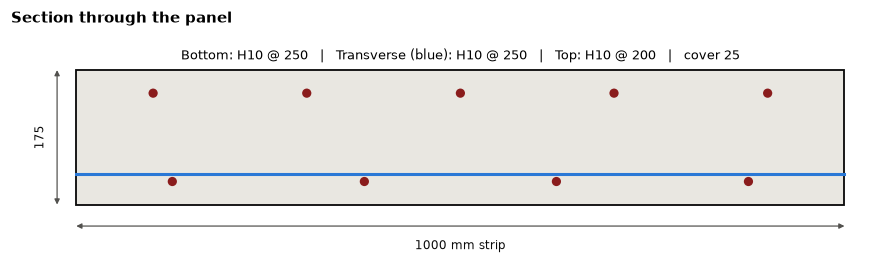

**Reinforcement schedule**

| Location | Provide |
|:--|:-:|
| Short span, bottom | H10 @ 250 (outer layer) |
| Long span, bottom | H10 @ 250 (inner layer) |
| Over Beam B (short-span support), top | H10 @ 200 |
| Over Beam 2 (long-span support), top | H10 @ 225 |
| Discontinuous edges and corners, top | H10 @ 250, 1000 mm at corners |


### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| two-way spanning | EC2 5.3.1(5) | 0.60 | ✅ PASS |
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| fire – slab thickness | EN 1992-1-2 5.7 | 0.46 | ✅ PASS |
| fire – axis distance | EN 1992-1-2 5.7 | 0.33 | ✅ PASS |
| singly reinforced (short span, mid-span) | EC2 5.5(4) | 0.15 | ✅ PASS |
| area provided short span, mid-span | EC2 6.1, 9.3.1.1 | 0.85 | ✅ PASS |
| maximum spacing short span, mid-span | EC2 9.3.1.1(3) | 1.00 | ✅ PASS |
| maximum steel short span, mid-span | EC2 9.2.1.1(3) | 0.04 | ✅ PASS |
| singly reinforced (short span, support) | EC2 5.5(4) | 0.20 | ✅ PASS |
| area provided short span, support | EC2 6.1, 9.3.1.1 | 0.91 | ✅ PASS |
| maximum spacing short span, support | EC2 9.3.1.1(3) | 0.80 | ✅ PASS |
| maximum steel short span, support | EC2 9.2.1.1(3) | 0.06 | ✅ PASS |
| singly reinforced (long span, mid-span) | EC2 5.5(4) | 0.13 | ✅ PASS |
| area provided long span, mid-span | EC2 6.1, 9.3.1.1 | 0.66 | ✅ PASS |
| maximum spacing long span, mid-span | EC2 9.3.1.1(3) | 1.00 | ✅ PASS |
| maximum steel long span, mid-span | EC2 9.2.1.1(3) | 0.04 | ✅ PASS |
| singly reinforced (long span, support) | EC2 5.5(4) | 0.17 | ✅ PASS |
| area provided long span, support | EC2 6.1, 9.3.1.1 | 0.79 | ✅ PASS |
| maximum spacing long span, support | EC2 9.3.1.1(3) | 0.90 | ✅ PASS |
| maximum steel long span, support | EC2 9.2.1.1(3) | 0.05 | ✅ PASS |
| shear, no links needed long edge | EC2 6.2.1(3), 6.2.1(4) | 0.41 | ✅ PASS |
| shear, no links needed short edge | EC2 6.2.1(3), 6.2.1(4) | 0.37 | ✅ PASS |
| deflection (span/depth) | EC2 7.4.2 | 0.66 | ✅ PASS |
| crack control | EC2 7.3.3(1) | – | ✅ PASS |
| torsion steel at corner A1 | BS 8110-1 3.5.3.5, rule 5 | 0.64 | ✅ PASS |
| singly reinforced (discontinuous edge) | EC2 5.5(4) | 0.04 | ✅ PASS |
| area provided top, discontinuous edges and corners | EC2 6.1, 9.3.1.1 | 0.70 | ✅ PASS |
| maximum spacing top, discontinuous edges and corners | EC2 9.3.1.1(3) | 1.00 | ✅ PASS |
| maximum steel top, discontinuous edges and corners | EC2 9.2.1.1(3) | 0.04 | ✅ PASS |
| area provided edge strips | EC2 6.1, 9.3.1.1 | 0.70 | ✅ PASS |
| maximum spacing edge strips | EC2 9.3.1.1(3) | 0.62 | ✅ PASS |
| maximum steel edge strips | EC2 9.2.1.1(3) | 0.04 | ✅ PASS |

**All checks pass.**

In [9]:
s.let("A_s_x", res["short span, mid-span"][0], "mm²/m", "Steel required at mid-span, short span")
s.calc("A_s_tor1", "0.75*A_s_x", "mm²/m", "BS 8110-1 3.5.3.5, rule 5", "Corner A1 (both edges discontinuous): each of 4 layers")
s.calc("A_s_tor2", "0.5*A_s_tor1", "mm²/m", "BS 8110-1 3.5.3.5, rule 6", "Corners with one continuous edge")
s.calc("l_tor", "l_x*1000/5", "mm", "BS 8110-1 3.5.3.5, rule 5", "Extent from each edge")
s.let("A_mesh", min(D.area(p) * 1000 / q for p, q in (edge_bars, bars["short span, mid-span"], bars["long span, mid-span"])), "mm²/m", "Least of the top and bottom bars already present"); s.check("A_mesh", ">=", "A_s_tor1", "torsion steel at corner A1", "BS 8110-1 3.5.3.5, rule 5")
s.calc("m_edge", "0.25*m_sx_p", "kN·m/m", "EC2 9.3.1.2(2)", "Top moment at discontinuous edges (25%; 15% is the EC2 minimum at an end support)"); s.show("Corners")
D.flexure(s, s["m_edge"], 1000, s["d_x"], label="(discontinuous edge)"); D.slab_bars(s, *edge_bars, h, label="top, discontinuous edges and corners"); s.calc("l_top", "0.2*(l_x*1000 - t)", "mm", "EC2 9.3.1.2(2)", "Extension from the face"); s.show("Discontinuous edges")
s.calc("A_s_req", "A_s_min", "mm²/m", "BS 8110-1 3.5.3.5, rule 4", "Edge strips (outer 1/8 of the width)"); D.slab_bars(s, *edge_bars, h, peak=False, label="edge strips"); s.show("Edge strips")
P.slab_section(h, c, bars["short span, mid-span"], bars["short span, support"], bars["long span, mid-span"], "Section through the panel")
H = lambda t: f"H{t[0]} @ {t[1]}"
table([["Short span, bottom", H(bars["short span, mid-span"]) + " (outer layer)"], ["Long span, bottom", H(bars["long span, mid-span"]) + " (inner layer)"], ["Over Beam B (short-span support), top", H(bars["short span, support"])], ["Over Beam 2 (long-span support), top", H(bars["long span, support"])], ["Discontinuous edges and corners, top", f"{H(edge_bars)}, {s['l_tor']:.0f} mm at corners"]], ["Location", "Provide"], "Reinforcement schedule")
s.summary()